In [1]:
import importlib
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
from torch import load
import time

In [2]:
import sys
from pathlib import Path

project_root = Path("..").resolve()  # points to /project
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from functions_library import *

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
model_library_path = "C://Users//jonas//Desktop//Masters//Main//Masters_project//models_library//"
z_mass_hist_path = "C://Users//jonas//Desktop//Masters//Main//csv_files//"
z_mass_files = ["Z_mass_EGAM1.csv", "Z_mass_EGAM7.csv"]
full_z_mass_hist_path = [z_mass_hist_path + file for file in z_mass_files]

In [4]:
base_string = "C://Users//jonas//Desktop//Masters//Main//h5//"
data_strings = ["MC_EGAM1", "MC_EGAM7", "DATA_EGAM"]
name_strings = data_strings + ["MC_EGAM"]
full_strings = [base_string + data_string for data_string in data_strings]
h5_files_dir = data_loading.create_path_lists(full_strings, outputs=name_strings, mixing_list = [(0, 1)], seed=0)
h5_files_egam = h5_files_dir[name_strings[-1]]
h5_files_data = h5_files_dir[name_strings[-2]]

In [5]:
model_particle_size = []
model_names = ["origin", "pt", "eta", "phi", "e"]
for name in model_names:
    if name == "origin":
        small_dataset = dataset_classes.ZPairDataset(
            h5_files_egam[0],
            exclude_features = ["truth"],
            exclude_fields = ["truthOrigin", "truthType", "passid_VeryLoose", "passid_Loose", "passid_Medium", "passid_Tight"],
        )
    else:
        small_dataset = dataset_classes.ZPairDataset(
            h5_files_egam[0],
            exclude_features = ["truth"],
            exclude_fields = ["truthOrigin", "truthType", name],
        )
    particle_fields = [field for field in small_dataset.fields if not field.startswith("eventwise_")]
    event_fields = [field for field in small_dataset.fields if field.startswith("eventwise_")]
    model_particle_size.append(len(particle_fields) // 2)
    if len(particle_fields) % 2 != 0:
        raise ValueError("Pair particle fields are not evenly split between the two particles.")


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
bins = np.arange(55.05, 135.05, 0.1)
model_paths = [model_library_path + "model_" + name + "_pair.pth" for name in model_names]
models = {}
for name, path, size in zip(model_names, model_paths, model_particle_size):
    print(f"Loading model {name} from {path}")
    if name == "origin":
        output_size = 1
    else:
        output_size = 4
    model = neural_models.ParticlePairNetwork(
        size,
        len(event_fields),
        particle_hidden_sizes=[1024, 256, 256, 256, 256, 256, 64, 8],
        event_hidden_sizes=[64, 64, 16, 4],
        consolidation_hidden_sizes=[32, 32, 32, 8],
        output_size=output_size,
    ).to(device)
    model.load_state_dict(torch.load(path))
    model.eval()
    models[name] = model


Loading model origin from C://Users//jonas//Desktop//Masters//Main//Masters_project//models_library//model_origin_pair.pth
Loading model pt from C://Users//jonas//Desktop//Masters//Main//Masters_project//models_library//model_pt_pair.pth
Loading model eta from C://Users//jonas//Desktop//Masters//Main//Masters_project//models_library//model_eta_pair.pth
Loading model phi from C://Users//jonas//Desktop//Masters//Main//Masters_project//models_library//model_phi_pair.pth
Loading model e from C://Users//jonas//Desktop//Masters//Main//Masters_project//models_library//model_e_pair.pth


In [ ]:
Output_Ns = misc_functions.create_pseudo_roc_curve(full_z_mass_hist_path, h5_files_egam[:3], h5_files_data[:3], models, device, bins = bins, num_workers = 8, pin_memory = False, n_total = 100)

Creating pseudo ROC curve with 100 thresholds.
Getting base truth totals for MC files...
Prediction completed                                                                                                                                                                                                                                                                                        
Predicting the Z masses for MC and data files...
Predicting pt for Z mass calculation...
Prediction completed                                                                                                                                                                                                                                                                                        
Predicting eta for Z mass calculation...
Prediction completed                                                                                                                                                               

In [ ]:
particle_fields = [field for field in val_dataset.fields if not field.startswith("eventwise_")]
event_fields = [field for field in val_dataset.fields if field.startswith("eventwise_")]
particle_size = len(particle_fields) // 2
if len(particle_fields) % 2 != 0:
    raise ValueError("Pair particle fields are not evenly split between the two particles.")

model = neural_models.ParticlePairNetwork(
    particle_size,
    len(event_fields),
    particle_hidden_sizes=[1024, 256, 256, 256, 256, 256, 64, 8],
    event_hidden_sizes=[64, 64, 16, 4],
    consolidation_hidden_sizes=[32, 32, 32, 8],
    output_size=1,
).to(device)

model_name = "model_pt_pair.pth"

model.load_state_dict(load(model_library_path+model_name, map_location=device))

In [ ]:
ps_med = []
ps_tight = []
truth = []
for batch in val_loader:
    _, _, event, target, _ = batch
    truth.append(target[:, 0])
    ps_tight.append(target[:, 1])
    ps_med.append(target[:, 2])

ps_med = np.concatenate(ps_med, axis=0)
ps_tight = np.concatenate(ps_tight, axis=0)
truth = np.concatenate(truth, axis=0) == 13
truth = truth.reshape(-1, 2)
truth = truth[:, 0] * truth[:, 1]
ps_med = ps_med.reshape(-1, 2)
ps_med = ps_med[:, 0] * ps_med[:, 1]
ps_tight = ps_tight.reshape(-1, 2)
ps_tight = ps_tight[:, 0] * ps_tight[:, 1]

predictions = model_training.predict(model, val_loader, device='cpu', means=means, stds=stds)

c:\Users\jonas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Prediction completed


In [ ]:
cut_labels = (ps_med > 0.5)
cut_true_positives = truth * cut_labels
#cut_false_negatives = targets * (1 - cut_labels)
#cut_true_negatives = (1 - targets) * (1 - cut_labels)
cut_false_positives = (1 - truth) * cut_labels
N_tp_cut = cut_true_positives.sum()
N_tn_cut = cut_false_positives.sum()
    

Num = 500
N_tp = np.zeros(Num)
N_tn = np.zeros(Num)
for i in range(Num):
    predicted_labels = (predictions > -10 + 20*i/Num).astype(bool)
    true_positives = truth * predicted_labels
    #false_negatives = targets * (1 - predicted_labels)
    #true_negatives = (1 - targets) * (1 - predicted_labels)
    false_positives = (1 - truth) * predicted_labels
    N_tp[i] = true_positives.sum()
    N_tn[i] = false_positives.sum()

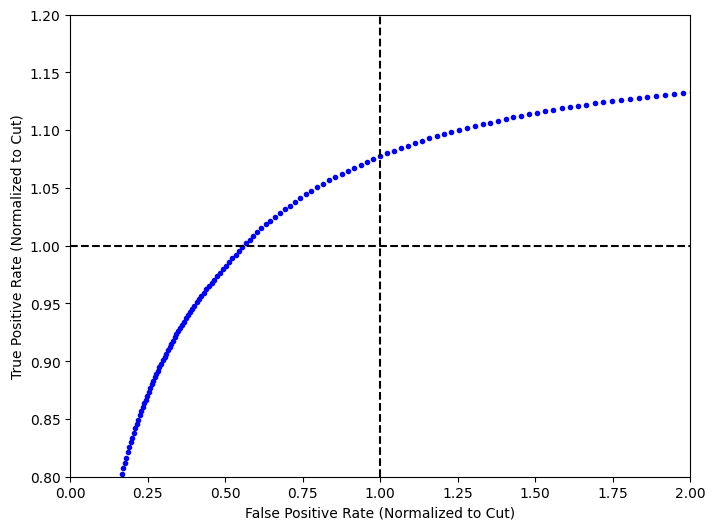

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(N_tn/N_tn_cut, N_tp/N_tp_cut, '.', color='blue', label='ML Model')
plt.axhline(1, color='black', linestyle='--', label='Cut True Positive Rate')
plt.axvline(1, color='black', linestyle='--', label='Cut False Positive Rate')
plt.xlabel('False Positive Rate (Normalized to Cut)')
plt.ylabel('True Positive Rate (Normalized to Cut)')
plt.xlim(0.0, 2.0)
plt.ylim(0.8, 1.2)
plt.show()

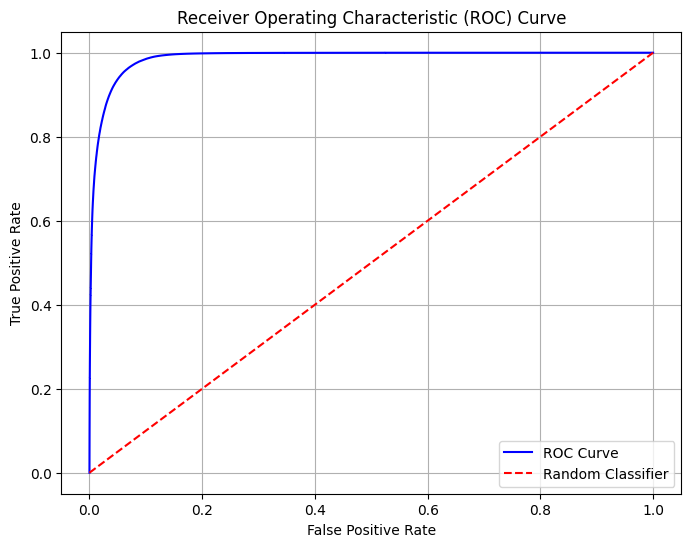

In [ ]:
roc_curve_data = roc_curve(targets, predictions)
plt.figure(figsize=(8, 6))
plt.plot(roc_curve_data[0], roc_curve_data[1], color='blue', label='ROC Curve')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid()


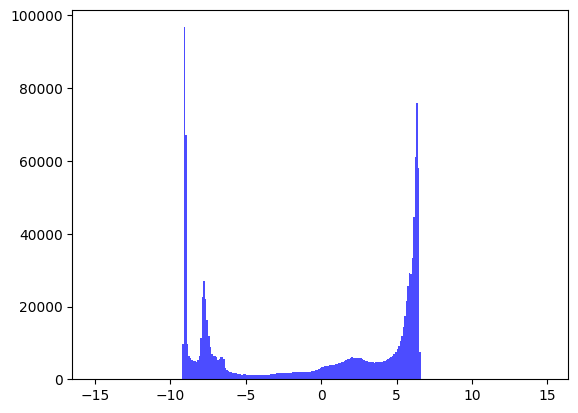

In [ ]:
plt.hist(predictions, bins=np.arange(-15, 15, 0.1), alpha=0.7, label='Predictions', color='blue')
plt.show()

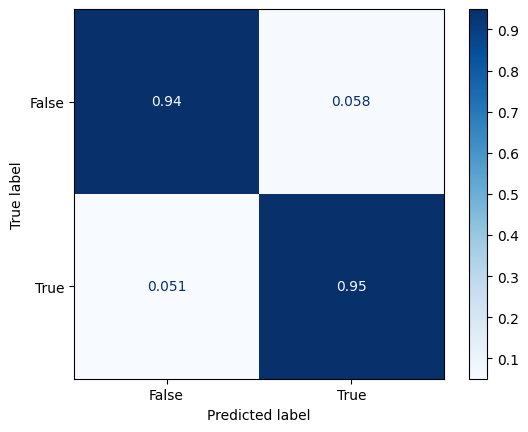

In [ ]:
cm = confusion_matrix(targets, predictions > 1.2, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[False, True])
disp.plot(cmap=plt.cm.Blues)